This notebook ('diann_peptide_ids_at_rts.ipynb') reads and filters the main report from DIANN output (report.parquet), selects runs for defined conditions, and analyzes the number of identified peptides across retention time, aligning each condition's retention time axis to zero at its first occupied bin.
Results are exported as individual .csv files (per-peptide shifted RTs, binned peptide counts, and alignment shift values) together with summary plots, separately for forward and reverse flush modes.

**Workflow overview:**

1. **Setup** – Import packages, set working directory, import custom `diann_main_report_filtering` module, enable autoreload, configure pandas display options.
2. **Define paths** – Set `input_dir` / `output_dir` for the dataset to process.
3. **Load report** – Read DIA-NN's `report.parquet` into a pandas DataFrame.
4. **FDR filtering** – Sequentially filter the main report at 1% precursor Q.Value (run-specific and global) and 1% global protein group Q.Value, plus a lenient Quantity.Quality cutoff (≥ 0.5).
5. **Run selection** – Define forward and reverse flush run lists per condition (pepmap, nanoshield_tht021_flip, direct_injection) and subset the filtered report into `main_report_pd_fil_for` / `main_report_pd_fil_rev`.
6. **Condition assignment & completeness filtering** – Map acquisition dates to condition names, then retain only peptides (Stripped.Sequence) identified in all replicates within their own condition (charge states collapsed).
7. **RT zero-alignment** – Compute one representative (mean) RT per peptide per condition, bin each condition's raw RTs into `N_BINS` bins, and derive a per-condition constant shift so the first occupied bin starts at RT = 0; apply the shift to all peptides of that condition.
8. **Binning & counting** – Re-bin the globally shifted RT range into `N_BINS` equal-width bins and count unique identified peptides per condition per bin, filling empty bins with zero.
9. **Export & plot** – For each flush mode (forward, reverse), export per-peptide shifted RTs, binned peptide counts, and shift values as `.csv` files, and save/display a line plot of identified peptides vs. zero-aligned retention time per condition.

In [1]:
# import relevant packages
import sys
import os
import inspect
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from textwrap import dedent
import seaborn as sns

# change working direction - point to where your notebooks (.ipynb) and python files (.py) are placed
new_cwd = Path("Z:/user/Dennis/trap_column_test/manuscript/diann_processing/jupyter_notebooks/github/")
os.chdir(new_cwd)
# verify new working directory
print("Current working directory:\n",os.getcwd())

# import custom functions
import diann_main_report_filtering as diann_filter

# auto reload of imported packages
%load_ext autoreload
%autoreload 2

# check where python is looking for path to resolve imports and where it actually loaded the packages from
print(f"This is where python is looking for packages:\n{sys.path}\n\n")

# change display settings for pandas dataframes
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)

# set to back to default if needed
#pd.reset_option("display.max_columns")
#pd.reset_option("display.max_rows")
    
# check current working directory of this notebook
print("Current working directory:")
!pwd

Current working directory:
 Z:\user\Dennis\trap_column_test\manuscript\diann_processing\jupyter_notebooks\github
This is where python is looking for packages:
['C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\python313.zip', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\DLLs', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test', '', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib\\site-packages', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib\\site-packages\\win32', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib\\site-packages\\win32\\lib', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib\\site-packages\\Pythonwin']


Current working directory:
/z/user/Dennis/

In [2]:
# define input and output directories for each acquired dataset

input_dir = Path("Z:/user/Dennis/trap_column_test/manuscript/diann_processing/dataset_g_combined/")
output_dir = Path("Z:/user/Dennis/trap_column_test/manuscript/diann_processing/dataset_g_combined/github_test/peptide_ids_at_rts/")

In [3]:
# read dianns main output parquet file as a pandas dataframe

# define input file name
input_file_name = "report.parquet"
# define input file path
input_file_path = input_dir / input_file_name
# read parquet file as pd dataframe
main_report_pd = pd.read_parquet(input_file_path, engine='pyarrow')
print("DIANN's parquet file was read in as a pandas dataframe.")

DIANN's parquet file was read in as a pandas dataframe.


In [4]:
# perform basic FDR filtering of loaded main report, "main_report_pd"

# filters sequentially, overwriting the variable to save memory
main_report_pd_fil = diann_filter.filter_dataframe(df=main_report_pd, column="Q.Value", cutoff=0.01, smaller_than=True, filter_proteotypic=False) # default precursor filtering at 1%, run-specific
main_report_pd_fil = diann_filter.filter_dataframe(df=main_report_pd_fil, column="Global.Q.Value", cutoff=0.01, smaller_than=True, filter_proteotypic=False) # precursor filtering at 1%, global
main_report_pd_fil = diann_filter.filter_dataframe(df=main_report_pd_fil, column="Global.PG.Q.Value", cutoff=0.01, smaller_than=True, filter_proteotypic=False) # protein group filtering at 1%, global
# lenient, retain the vast majority of IDs, drop only clearly bad ones - quality of precursor quantity, is it trustworthy
main_report_pd_fil = diann_filter.filter_dataframe(df=main_report_pd_fil, column="Quantity.Quality", cutoff=0.5, smaller_than=False, filter_proteotypic=False)
# reset index after filtering to maintain a clean sequence
main_report_pd_fil.reset_index(drop=True, inplace=True)
print("Dataframe was filtered successfully")

Dataframe was filtered successfully


In [5]:
# higher level conditions and run selection

# define selected runs
run_sel_for = [
  # pepmap - forward
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_1",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_2",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_3",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_4",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_5",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_6",
  # nanoshield tht021 flipped - forward
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_1",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_2",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_3",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_4",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_5",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_6",
  # direct injection
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_1",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_2",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_3",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_4",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_5",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_6", 
]

run_sel_rev = [
  # pepmap - reverse
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_1",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_2",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_3",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_4",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_5",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_6",
  # nanoshield tht021 flipped - reverse
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_1",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_2",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_3",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_4",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_5",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_6",
  # direct injection
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_1",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_2",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_3",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_4",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_5",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_6", 
]

# select runs from main report using exact matching for "Run" name - main_report_pd_fil_for is main dataframe used for all analyses below - forward
main_report_pd_fil_for = main_report_pd_fil[main_report_pd_fil["Run"].isin(run_sel_for)].copy()
print("Selection is done - forward")
# select runs from main report using exact matching for "Run" name - main_report_pd_fil_rev is main dataframe used for all analyses below - reverse
main_report_pd_fil_rev = main_report_pd_fil[main_report_pd_fil["Run"].isin(run_sel_rev)].copy()
print("Selection is done - reverse")

Selection is done - forward
Selection is done - reverse


Filtering for peptides present in all replicates of their condition is done (forward): 27590 unique peptides retained overall
  [forward] RT zero-alignment 'pepmap': first occupied bin left edge = 2.525 min -> shift = -2.525 min
  [forward] Derived constant RT shifts: pepmap = -2.525 min
  [forward] RT zero-alignment 'nanoshield_tht021_flip': first occupied bin left edge = 1.586 min -> shift = -1.586 min
  [forward] Derived constant RT shifts: pepmap = -2.525 min, nanoshield_tht021_flip = -1.586 min
  [forward] RT zero-alignment 'direct_injection': first occupied bin left edge = 0.563 min -> shift = -0.563 min
  [forward] Derived constant RT shifts: pepmap = -2.525 min, nanoshield_tht021_flip = -1.586 min, direct_injection = -0.563 min


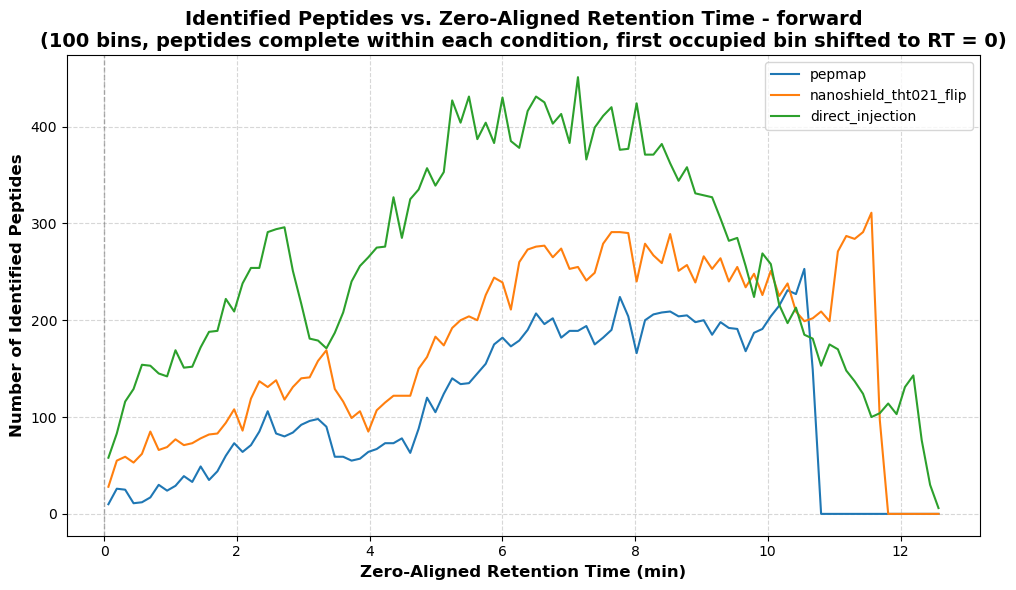

Saved → Z:\user\Dennis\trap_column_test\manuscript\diann_processing\dataset_g_combined\github_test\peptide_ids_at_rts\identified_peptides_vs_rt_zero_aligned_forward_100_bins.png
Filtering for peptides present in all replicates of their condition is done (reverse): 31159 unique peptides retained overall
  [reverse] RT zero-alignment 'pepmap': first occupied bin left edge = 2.525 min -> shift = -2.525 min
  [reverse] Derived constant RT shifts: pepmap = -2.525 min
  [reverse] RT zero-alignment 'nanoshield_tht021_flip': first occupied bin left edge = 1.589 min -> shift = -1.589 min
  [reverse] Derived constant RT shifts: pepmap = -2.525 min, nanoshield_tht021_flip = -1.589 min
  [reverse] RT zero-alignment 'direct_injection': first occupied bin left edge = 0.563 min -> shift = -0.563 min
  [reverse] Derived constant RT shifts: pepmap = -2.525 min, nanoshield_tht021_flip = -1.589 min, direct_injection = -0.563 min


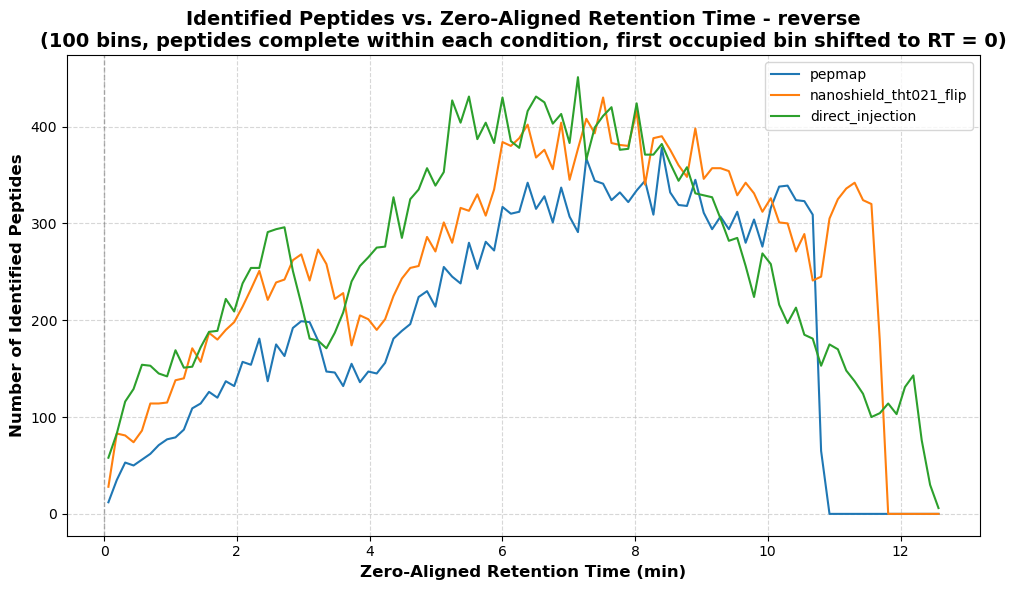

Saved → Z:\user\Dennis\trap_column_test\manuscript\diann_processing\dataset_g_combined\github_test\peptide_ids_at_rts\identified_peptides_vs_rt_zero_aligned_reverse_100_bins.png


In [6]:
# ── identified peptides vs. (zero-aligned) retention time, per condition ───
# - filtering: peptides (Stripped.Sequence) must be identified in ALL replicates
#   of a given condition (charge states collapsed); peptides do NOT need to be
#   shared across conditions for the completeness filter itself
# - RT ZERO-ALIGNMENT (constant offset, per condition, derived from binning):
#   each condition's peptides are first binned into N_BINS bins using that
#   condition's OWN raw RT range. The left edge of the first (lowest-RT) bin
#   that actually contains identified peptides defines the per-condition
#   shift: shift = -(left edge of first occupied bin). This constant shift is
#   then applied to ALL peptides of that condition, so that the first bin with
#   any identified peptides starts at RT = 0. No anchor peptides or shared
#   identifications across conditions are required - each condition is
#   zero-aligned independently.
# - each peptide is assigned a single representative RT (mean RT across all its
#   observations - replicates and charge states - within that condition),
#   calculated BEFORE shifting, then shifted
# - after zero-alignment, the (shifted) RT axis is re-binned into N_BINS equal-
#   width bins using the GLOBAL shifted-RT range, so bins are directly
#   comparable across conditions for the final plot
# - results are plotted as one line per condition
# - forward and reverse flush modes are processed and plotted separately

N_BINS = 100  # user-controlled parameter: number of retention time bins

# create a mapping dictionary for the conditions
date_to_condition = {
    "20260911": "pepmap",
    "20260914": "nanoshield_tht021_flip",
    "20260916": "direct_injection"
}

conditions = ["pepmap", "nanoshield_tht021_flip", "direct_injection"]

# 2. filter for peptides (Stripped.Sequence) identified in ALL replicates WITHIN each condition
#    (charge states collapsed - a peptide only needs ANY precursor charge to be seen in a run
#    for that run to count as an identification of the peptide)
def filter_peptides_complete_within_condition(df, seq_col="Stripped.Sequence"):
    # required run count per condition (number of replicates for that condition)
    req_counts = df.groupby("Condition")["Run"].nunique()
    # count how many runs each (Condition, Stripped.Sequence) pair was actually seen in
    seq_counts = df.groupby(["Condition", seq_col])["Run"].nunique().reset_index(name="n_runs")
    seq_counts["required"] = seq_counts["Condition"].map(req_counts)
    # keep only (Condition, Stripped.Sequence) pairs complete within their own condition
    complete_pairs = seq_counts[seq_counts["n_runs"] == seq_counts["required"]]
    valid_pairs = set(zip(complete_pairs["Condition"], complete_pairs[seq_col]))
    mask = df.apply(lambda row: (row["Condition"], row[seq_col]) in valid_pairs, axis=1)
    return df[mask].copy()

# derive the zero-alignment shift for a single condition: bin that condition's
# own (raw) peptide RTs into N_BINS bins over its own RT range, find the left
# edge of the first bin containing at least one identified peptide, and return
# the shift that would move that edge to RT = 0 (shift = -left_edge).
def fit_rt_zero_alignment_shift(rt_values, n_bins=N_BINS):
    rt_min = rt_values.min()
    rt_max = rt_values.max()
    bin_edges = np.linspace(rt_min, rt_max, n_bins + 1)
    bin_idx = pd.cut(rt_values, bins=bin_edges, include_lowest=True, labels=False)
    occupied_bins = np.sort(pd.unique(bin_idx[~pd.isna(bin_idx)].astype(int)))
    first_occupied_bin = occupied_bins[0]
    first_bin_left_edge = bin_edges[first_occupied_bin]
    shift = -first_bin_left_edge
    return shift, first_bin_left_edge

# ── loop over forward and reverse flush modes separately ───────────────────
for flush_label, df_source in [
    ("forward", main_report_pd_fil_for),
    ("reverse", main_report_pd_fil_rev),
]:

    # copy main report for this flush mode
    main_report_pd_fil_rt_pep = df_source.copy()

    # 1. extract the first 8 characters from the "Run" column (acquisition date) and map these dates to the condition names
    main_report_pd_fil_rt_pep["Condition"] = (
        main_report_pd_fil_rt_pep["Run"].astype(str).str[:8].map(date_to_condition)
    )

    main_report_pd_fil_rt_pep_cons = filter_peptides_complete_within_condition(main_report_pd_fil_rt_pep)
    print(
        f"Filtering for peptides present in all replicates of their condition is done ({flush_label}):",
        main_report_pd_fil_rt_pep_cons["Stripped.Sequence"].nunique(), "unique peptides retained overall"
    )

    # 3. calculate one representative (raw) RT per peptide per condition (mean RT across all
    #    observations - replicates and charge states - of that peptide within the condition)
    peptide_rt = (
        main_report_pd_fil_rt_pep_cons
        .groupby(["Condition", "Stripped.Sequence"])["RT"]
        .mean()
        .reset_index()
    )

    # 3b. RT zero-alignment - derive and apply a constant per-condition shift so that
    #     the first RT bin containing identified peptides starts at RT = 0
    peptide_rt["RT_Shifted"] = peptide_rt["RT"]  # overwritten per condition below
    shifts = {}
    first_edges = {}
    for cond in conditions:
        cond_mask = peptide_rt["Condition"] == cond
        rt_values = peptide_rt.loc[cond_mask, "RT"]
        shift, first_bin_left_edge = fit_rt_zero_alignment_shift(rt_values, n_bins=N_BINS)
        shifts[cond] = shift
        first_edges[cond] = first_bin_left_edge
        print(f"  [{flush_label}] RT zero-alignment '{cond}': first occupied bin left edge = "
              f"{first_bin_left_edge:.3f} min -> shift = {shift:+.3f} min")
        peptide_rt.loc[cond_mask, "RT_Shifted"] = rt_values + shift
  
        print(f"  [{flush_label}] Derived constant RT shifts: " +  
              ", ".join(f"{cond} = {shift:+.3f} min" for cond, shift in shifts.items()))  
  
    # 4. bin the (shifted) retention time axis into N_BINS equal-width bins, using the
    #    global shifted-RT range so bins are directly comparable across conditions
    rt_min = peptide_rt["RT_Shifted"].min()
    rt_max = peptide_rt["RT_Shifted"].max()
    bin_edges = np.linspace(rt_min, rt_max, N_BINS + 1)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    peptide_rt["RT_Bin"] = pd.cut(peptide_rt["RT_Shifted"], bins=bin_edges, include_lowest=True, labels=False)

    # 5. count number of (unique) identified peptides per condition per RT bin
    peptide_counts = (
        peptide_rt.groupby(["Condition", "RT_Bin"])["Stripped.Sequence"]
        .nunique()
        .reset_index(name="Peptide_Count")
    )

    # 6. reindex so every condition has an entry for every bin (0 where no peptides fall into a bin)
    full_index = pd.MultiIndex.from_product([conditions, range(N_BINS)], names=["Condition", "RT_Bin"])
    peptide_counts = (
        peptide_counts.set_index(["Condition", "RT_Bin"])
        .reindex(full_index, fill_value=0)
        .reset_index()
    )
    # map bin index to the bin center (shifted) RT value for plotting on a continuous x-axis
    peptide_counts["RT_Bin_Center"] = peptide_counts["RT_Bin"].map(lambda i: bin_centers[i])

    # 7. export raw data (including per-peptide shifted RTs and the applied shifts) as .csv
    peptide_rt.to_csv(output_dir / f"peptide_rt_zero_alignment_{flush_label}.csv", index=False)
    peptide_counts.to_csv(output_dir / f"identified_peptides_vs_rt_zero_aligned_{flush_label}_{N_BINS}_bins.csv", index=False)
    pd.DataFrame({
        "Condition": list(shifts.keys()),
        "First_Occupied_Bin_Left_Edge_Min": [first_edges[c] for c in shifts],
        "RT_Shift_Min": [shifts[c] for c in shifts],
    }).to_csv(output_dir / f"rt_zero_alignment_shift_values_{flush_label}.csv", index=False)

    # 8. plot: one line per condition
    plt.figure(figsize=(10, 6))
    sns.lineplot(
        data=peptide_counts,
        x="RT_Bin_Center",
        y="Peptide_Count",
        hue="Condition",
        hue_order=conditions,
        marker=None,
        linewidth=1.5,
    )
    plt.axvline(0, color="gray", linestyle="--", linewidth=1, alpha=0.6)
    plt.xlabel("Zero-Aligned Retention Time (min)", fontsize=12, fontweight="semibold")
    plt.ylabel("Number of Identified Peptides", fontsize=12, fontweight="semibold")
    plt.title(
        f"Identified Peptides vs. Zero-Aligned Retention Time - {flush_label}\n"
        f"({N_BINS} bins, peptides complete within each condition, first occupied bin shifted to RT = 0)",
        fontsize=14, fontweight="bold",
    )
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend(title="", fontsize=10)
    plt.tight_layout()
    output_plot_path = output_dir / f"identified_peptides_vs_rt_zero_aligned_{flush_label}_{N_BINS}_bins.png"
    plt.savefig(output_plot_path, dpi=600, bbox_inches="tight")
    plt.show()
    print(f"Saved → {output_plot_path}")